# Assignment 1: What Drives Car Price? Exploratory Data Analysis

**Student:** Magala Muhusinu S26M19/046 |  **Dataset:** `automobileEDA.csv` (201 cars, 29 variables)
**Github Link** https://github.com/magala-muhsin/Data-Science-Lifecycle.git

**Objective:** use exploratory data analysis and statistical techniques to find the variables with the greatest impact on car price, and turn the findings into pricing advice for a dealer.

The notebook is organised by assignment question. Every code output is followed by a short explanation of what it shows.

---
## Question 1: Data exploration and cleaning
Loading the data and looking at its structure.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
import warnings
warnings.filterwarnings("ignore")

sns.set_theme(style="whitegrid")
df = pd.read_csv("automobileEDA.csv")
print("Shape:", df.shape)
df.head()

Shape: (201, 29)


,symboling,normalized-losses,make,aspiration,num-of-doors,body-style,drive-wheels,engine-location,wheel-base,length,...,compression-ratio,horsepower,peak-rpm,city-mpg,highway-mpg,price,city-L/100km,horsepower-binned,diesel,gas
0,3,122,alfa-romero,std,two,convertible,rwd,front,88.6,0.811148,...,9.0,111.0,5000.0,21,27,13495.0,11.190476,Medium,0,1
1,3,122,alfa-romero,std,two,convertible,rwd,front,88.6,0.811148,...,9.0,111.0,5000.0,21,27,16500.0,11.190476,Medium,0,1
2,1,122,alfa-romero,std,two,hatchback,rwd,front,94.5,0.822681,...,9.0,154.0,5000.0,19,26,16500.0,12.368421,Medium,0,1
3,2,164,audi,std,four,sedan,fwd,front,99.8,0.848630,...,10.0,102.0,5500.0,24,30,13950.0,9.791667,Medium,0,1
4,2,164,audi,std,four,sedan,4wd,front,99.4,0.848630,...,8.0,115.0,5500.0,18,22,17450.0,13.055556,Medium,0,1


The dataset has 201 rows and 29 columns. Each row is a car described by its make, body and engine specifications, fuel economy and `price`, which is the target variable.

In [2]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 201 entries, 0 to 200
Data columns (total 29 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   symboling          201 non-null    int64  
 1   normalized-losses  201 non-null    int64  
 2   make               201 non-null    str    
 3   aspiration         201 non-null    str    
 4   num-of-doors       201 non-null    str    
 5   body-style         201 non-null    str    
 6   drive-wheels       201 non-null    str    
 7   engine-location    201 non-null    str    
 8   wheel-base         201 non-null    float64
 9   length             201 non-null    float64
 10  width              201 non-null    float64
 11  height             201 non-null    float64
 12  curb-weight        201 non-null    int64  
 13  engine-type        201 non-null    str    
 14  num-of-cylinders   201 non-null    str    
 15  engine-size        201 non-null    int64  
 16  fuel-system        201 non-null    st

19 variables are numeric and 10 are text (categorical). Every column has 201 values except `stroke` (197) and `horsepower-binned` (200), so those two have missing values.
Note that `length` and `width` are already scaled to a 0-1 range in this file, so their units are not inches.

### 1.1 Missing values

In [3]:
missing = df.isnull().sum()
print(missing[missing > 0])
print("\nRows with missing stroke:", df[df["stroke"].isnull()].index.tolist())
print("Row with missing horsepower-binned:", df[df["horsepower-binned"].isnull()].index.tolist())

stroke               4
horsepower-binned    1
dtype: int64

Rows with missing stroke: [52, 53, 54, 55]
Row with missing horsepower-binned: [46]


Only 5 values are missing: 4 in `stroke` (rows 52-55) and 1 in `horsepower-binned` (row 46). That is a very small share of the data, so imputing is better than dropping rows.

### 1.2 Duplicates

In [4]:
print("Duplicate rows:", df.duplicated().sum())
df = df.drop_duplicates()
print("Shape after dropping duplicates:", df.shape)

Duplicate rows: 0
Shape after dropping duplicates: (201, 29)


There are 0 duplicate rows, so nothing was removed and the data keeps its 201 rows.

### 1.3 Variable types and handling missing values

In [5]:
num_cols = df.select_dtypes(include=np.number).columns.tolist()
cat_cols = df.select_dtypes(exclude=np.number).columns.tolist()
print("Numeric:", num_cols)
print("\nCategorical:", cat_cols)

Numeric: ['symboling', 'normalized-losses', 'wheel-base', 'length', 'width', 'height', 'curb-weight', 'engine-size', 'bore', 'stroke', 'compression-ratio', 'horsepower', 'peak-rpm', 'city-mpg', 'highway-mpg', 'price', 'city-L/100km', 'diesel', 'gas']

Categorical: ['make', 'aspiration', 'num-of-doors', 'body-style', 'drive-wheels', 'engine-location', 'engine-type', 'num-of-cylinders', 'fuel-system', 'horsepower-binned']


The numeric and categorical columns are separated so each type can be imputed appropriately.
`diesel` and `gas` are 0/1 dummy variables that carry the same information as fuel type.

In [6]:
for col in num_cols:
    if df[col].isnull().sum() > 0:
        df[col] = df[col].fillna(df[col].median())
for col in cat_cols:
    if df[col].isnull().sum() > 0:
        df[col] = df[col].fillna(df[col].mode()[0])
print("Missing values remaining:", df.isnull().sum().sum())

Missing values remaining: 0


0 missing values remain. Numeric gaps (`stroke`) were filled with the median, which is robust to outliers, and the categorical gap (`horsepower-binned`) with the mode (most common category).

### 1.4 Outliers
Boxplots first (one panel per variable because the scales differ), then the IQR rule: a value is an outlier if it lies more than 1.5 x IQR below Q1 or above Q3.

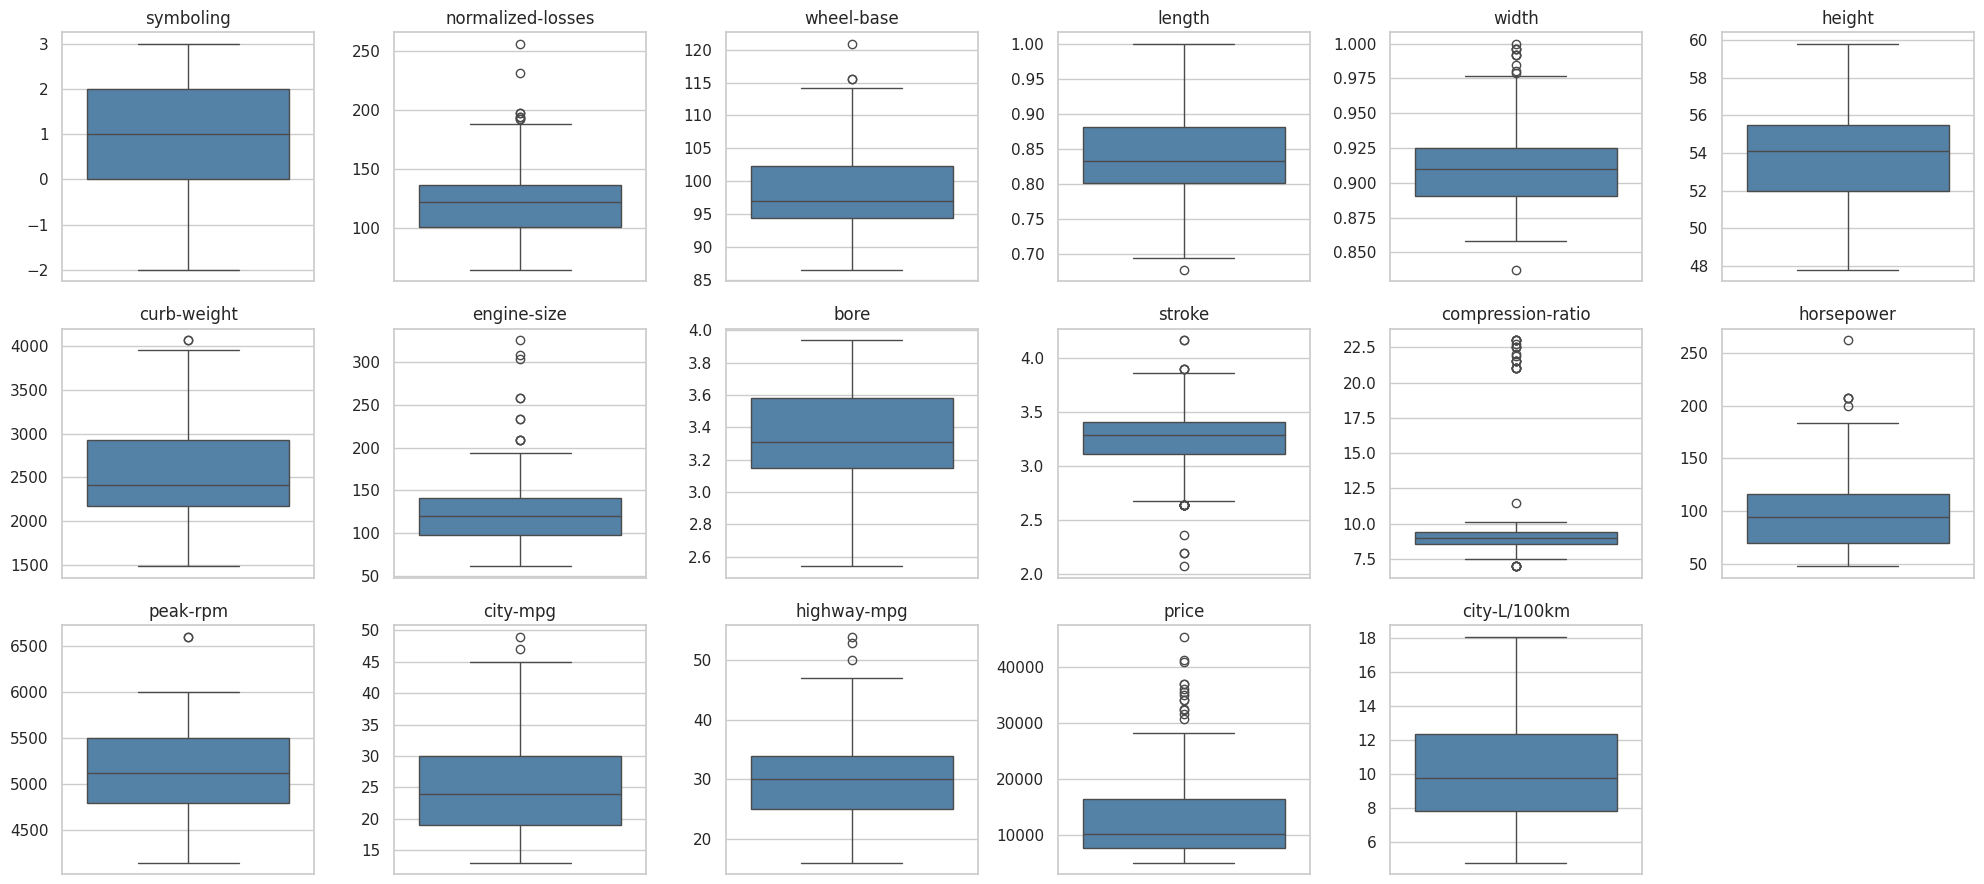

In [ ]:

box_cols = [c for c in num_cols if c not in ["diesel", "gas"]]
fig, axes = plt.subplots(3, 6, figsize=(20, 9))
for ax, col in zip(axes.ravel(), box_cols):
    sns.boxplot(y=df[col], ax=ax, color="steelblue")
    ax.set_title(col)
    ax.set_ylabel("")
for ax in axes.ravel()[len(box_cols):]:
    ax.axis("off")
plt.tight_layout()
plt.show()

Several variables show points beyond the whiskers, notably `price`, `engine-size`, `horsepower`, `curb-weight`, `width`, `wheel-base` and `compression-ratio`. `price` has a long upper tail, meaning a small group of very expensive cars.

In [8]:
def iqr_bounds(data, column):
    Q1, Q3 = data[column].quantile([0.25, 0.75])
    IQR = Q3 - Q1
    return Q1 - 1.5 * IQR, Q3 + 1.5 * IQR

rows = []
for col in ["price", "engine-size", "horsepower", "curb-weight"]:
    lo, hi = iqr_bounds(df, col)
    n = ((df[col] < lo) | (df[col] > hi)).sum()
    rows.append([col, round(lo, 1), round(hi, 1), n])
pd.DataFrame(rows, columns=["variable", "lower_bound", "upper_bound", "n_outliers"])

,variable,lower_bound,upper_bound,n_outliers
0,price,-5312.5,29587.5,14
1,engine-size,33.5,205.5,10
2,horsepower,1.0,185.0,5
3,curb-weight,1033.5,4061.5,2


The IQR rule flags 14 outliers in `price` (above 29,588), 10 in `engine-size`, 5 in `horsepower` and 2 in `curb-weight`. Next we check whether these are errors or real cars.

In [9]:
lo, hi = iqr_bounds(df, "price")
df.loc[df["price"] > hi, ["make", "body-style", "engine-size", "price"]].sort_values("price", ascending=False)

,make,body-style,engine-size,price
71,mercedes-benz,hardtop,304,45400.0
15,bmw,sedan,209,41315.0
70,mercedes-benz,sedan,308,40960.0
125,porsche,convertible,194,37028.0
16,bmw,sedan,209,36880.0
46,jaguar,sedan,326,36000.0
45,jaguar,sedan,258,35550.0
69,mercedes-benz,convertible,234,35056.0
68,mercedes-benz,sedan,234,34184.0
124,porsche,hardtop,194,34028.0


All 14 price outliers are luxury or performance models (Mercedes-Benz, BMW, Porsche and Jaguar) with large engines (engine-size 183 to 326). They are real vehicles, not data-entry errors.

In [10]:
# Decision: the extreme values are genuine luxury cars, not errors, so they are RETAINED (and flagged).
# First, show what capping would do to the relationship with price:
for col in ["engine-size", "horsepower", "curb-weight"]:
    lo, hi = iqr_bounds(df, col)
    capped = df[col].clip(lo, hi)
    print(f"{col:12s} r with price: original = {df[col].corr(df['price']):.3f} | if capped = {capped.corr(df['price']):.3f}")

# Flag the price outliers instead of altering them
lo, hi = iqr_bounds(df, "price")
df["price_outlier"] = (df["price"] > hi).astype(int)
print("Price outliers flagged:", df["price_outlier"].sum())

df.to_csv("Magala_Data.csv", index=False)
print("Saved cleaned data:", df.shape)

engine-size  r with price: original = 0.872 | if capped = 0.849
horsepower   r with price: original = 0.810 | if capped = 0.805
curb-weight  r with price: original = 0.834 | if capped = 0.834
Price outliers flagged: 14
Saved cleaned data: (201, 30)


**Decision on outliers:** the extreme values are genuine luxury cars, and they are exactly the cases where price is highest, so removing them would hide the pattern we want to explain. Capping would also weaken real signal: capping `engine-size` lowers its correlation with price from 0.872 to 0.849.
The outliers are therefore **retained**, and a `price_outlier` flag (14 cars) is added so they can be identified or excluded later. Imputation was the only value change. The cleaned dataset (201 rows, 30 columns) is saved as `Magala_Data.csv`.

---
## Question 2: Patterns and descriptive statistics
### 2.1 Summary statistics for the continuous variables

In [11]:
cont_cols = ["wheel-base", "length", "width", "height", "curb-weight", "engine-size", "bore", "stroke",
             "compression-ratio", "horsepower", "peak-rpm", "city-mpg", "highway-mpg", "city-L/100km",
             "normalized-losses", "price"]
summary = df[cont_cols].describe().T
summary["skew"] = df[cont_cols].skew()
summary.round(2)

,count,mean,std,min,25%,50%,75%,max,skew
wheel-base,201.0,98.80,6.07,86.60,94.50,97.00,102.40,120.90,1.03
length,201.0,0.84,0.06,0.68,0.80,0.83,0.88,1.00,0.15
width,201.0,0.92,0.03,0.84,0.89,0.91,0.92,1.00,0.88
height,201.0,53.77,2.45,47.80,52.00,54.10,55.50,59.80,0.03
curb-weight,201.0,2555.67,517.30,1488.00,2169.00,2414.00,2926.00,4066.00,0.71
engine-size,201.0,126.88,41.55,61.00,98.00,120.00,141.00,326.00,1.98
bore,201.0,3.33,0.27,2.54,3.15,3.31,3.58,3.94,-0.03
stroke,201.0,3.26,0.32,2.07,3.11,3.29,3.41,4.17,-0.71
compression-ratio,201.0,10.16,4.00,7.00,8.60,9.00,9.40,23.00,2.58
horsepower,201.0,103.41,37.37,48.00,70.00,95.00,116.00,262.00,1.15


The average car costs about 13,207 (median 10,295), with prices from 5,118 to 45,400. The mean is well above the median and the skewness is 1.81, so price is strongly right-skewed.
Engine size averages about 124 and horsepower about 103, while `curb-weight` averages about 2,556. `compression-ratio` is also very skewed (2.58) with a maximum of 23: the 20 cars above 15 are all diesel engines, which is normal for diesels.

### 2.2 Frequency counts for the categorical variables

In [12]:
freq_cols = ["make", "aspiration", "num-of-doors", "body-style", "drive-wheels", "engine-location",
             "engine-type", "num-of-cylinders", "fuel-system", "horsepower-binned"]
for col in freq_cols:
    counts = df[col].value_counts()
    print(pd.DataFrame({"count": counts, "percent": (counts / len(df) * 100).round(1)}))
    print()

               count  percent
make                         
toyota            32     15.9
nissan            18      9.0
mazda             17      8.5
honda             13      6.5
mitsubishi        13      6.5
subaru            12      6.0
volkswagen        12      6.0
peugot            11      5.5
volvo             11      5.5
dodge              9      4.5
bmw                8      4.0
mercedes-benz      8      4.0
plymouth           7      3.5
audi               6      3.0
saab               6      3.0
porsche            4      2.0
alfa-romero        3      1.5
chevrolet          3      1.5
jaguar             3      1.5
isuzu              2      1.0
renault            2      1.0
mercury            1      0.5

            count  percent
aspiration                
std           165     82.1
turbo          36     17.9

              count  percent
num-of-doors                
four            115     57.2
two              86     42.8

             count  percent
body-style               

**Output (patterns in the categories):**
- The market is dominated by ordinary cars: toyota is the most frequent make (32 cars, 15.9%), followed by nissan (18) and mazda (17). Premium makes such as jaguar (3) and porsche (4) are rare.
- Sedans (46.8%) and hatchbacks (33.8%) make up most of the body styles; convertibles (6) and hardtops (8) are scarce.
- Front-wheel drive is the majority (58.7%), rear-wheel drive 37.3%, and 4wd only 4.0% (8 cars).
- Almost all cars have a front engine (98.5%), a standard (non-turbo) engine (82.1%) and four cylinders (78.1%).
- Small groups (e.g. 4wd, rear engine, 12-cylinder) will give less reliable averages later.

### 2.3 Distribution of price and of the other variables

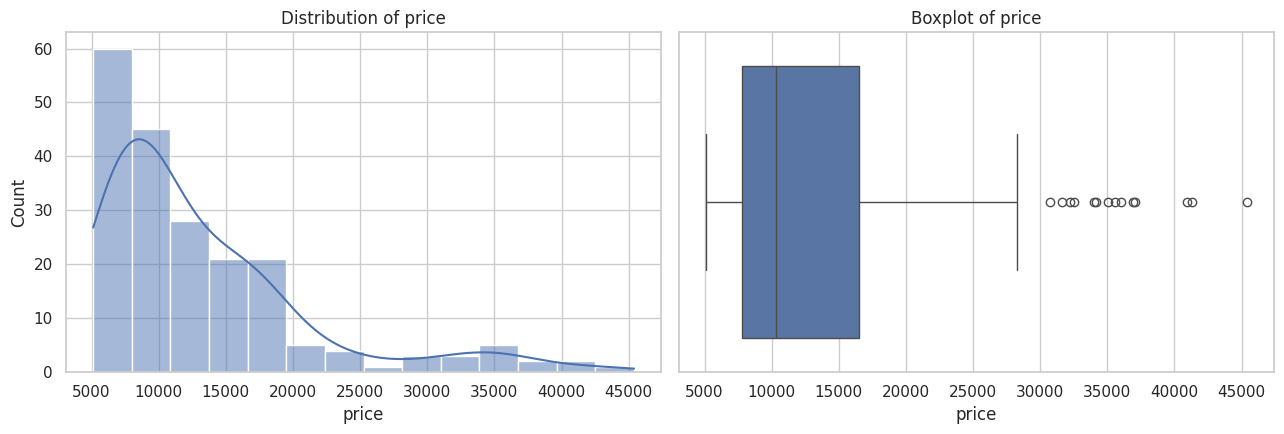

Skewness of price: 1.81
Mean: 13207 | Median: 10295


In [13]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
sns.histplot(df["price"], kde=True, ax=axes[0])
axes[0].set_title("Distribution of price")
sns.boxplot(x=df["price"], ax=axes[1])
axes[1].set_title("Boxplot of price")
plt.tight_layout()
plt.show()
print("Skewness of price:", round(df["price"].skew(), 2))
print("Mean:", round(df["price"].mean()), "| Median:", round(df["price"].median()))

Most cars are priced between roughly 5,000 and 17,000, with a long tail up to 45,400. The boxplot confirms the right skew (1.81), and the mean (13,207) sits above the median (10,295). A typical car is therefore cheaper than the average suggests, and a few luxury models pull the average up.

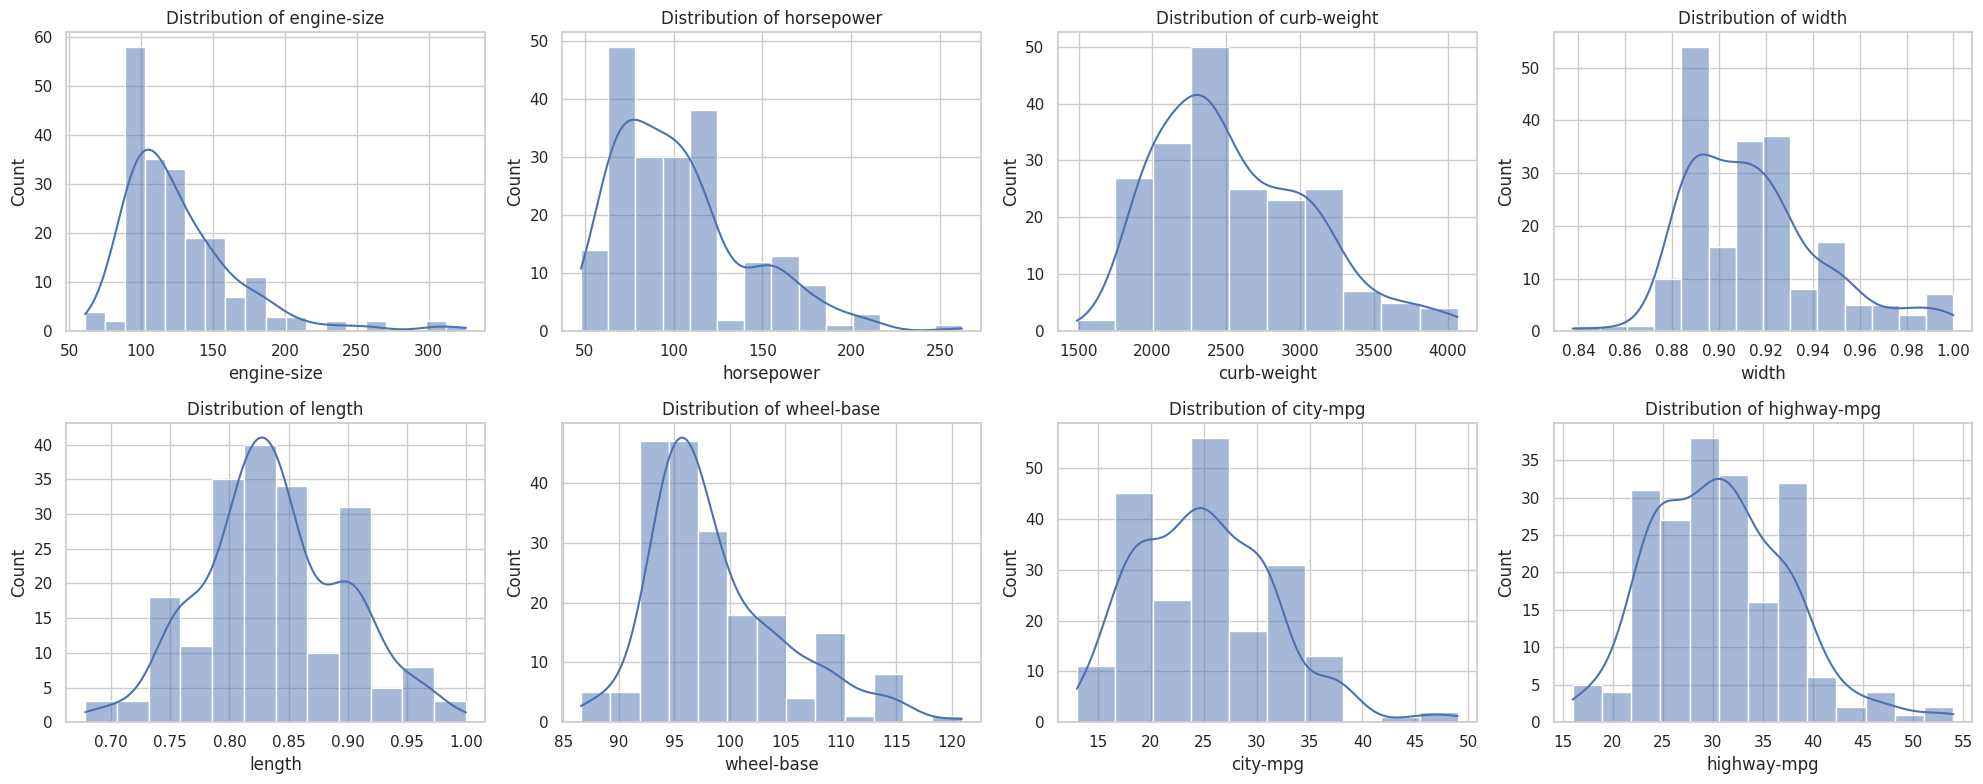

In [14]:
hist_cols = ["engine-size", "horsepower", "curb-weight", "width", "length", "wheel-base", "city-mpg", "highway-mpg"]
fig, axes = plt.subplots(2, 4, figsize=(20, 8))
for ax, col in zip(axes.ravel(), hist_cols):
    sns.histplot(df[col], kde=True, ax=ax)
    ax.set_title(f"Distribution of {col}")
plt.tight_layout()
plt.show()

`engine-size`, `horsepower`, `curb-weight`, `width` and `wheel-base` are right-skewed: most cars are small and light, with a few large, powerful ones. `city-mpg` and `highway-mpg` are also mildly skewed, with most cars at roughly 19-30 city-mpg and 25-34 highway-mpg. This mirrors the shape of price, which hints that these variables move together with price.

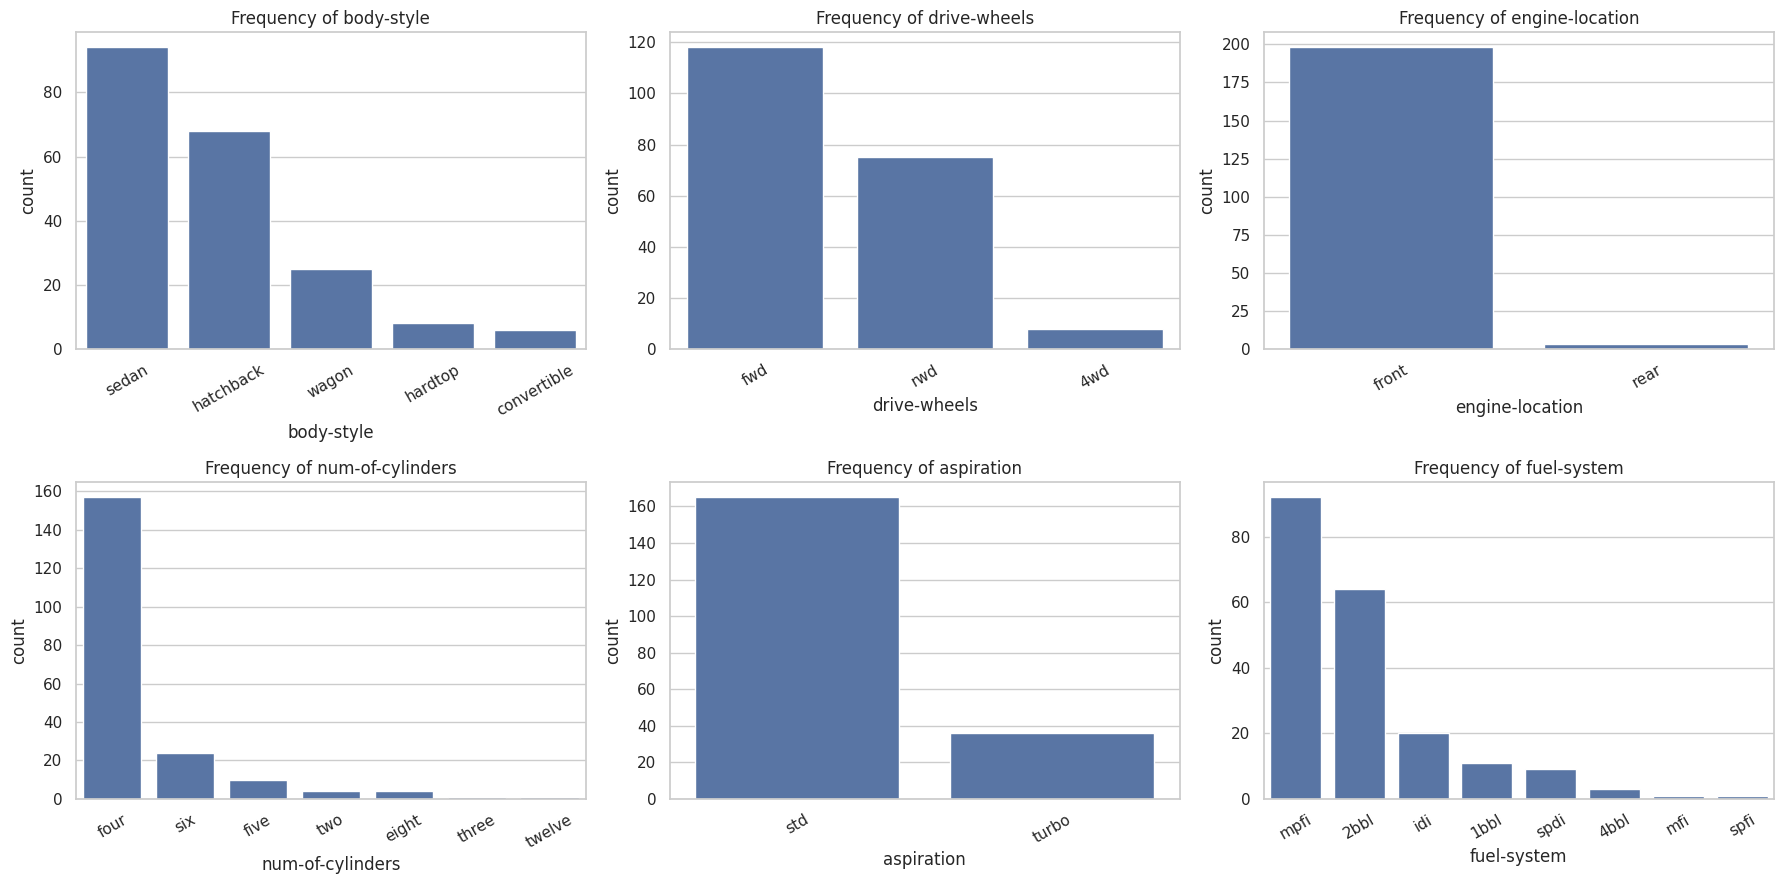

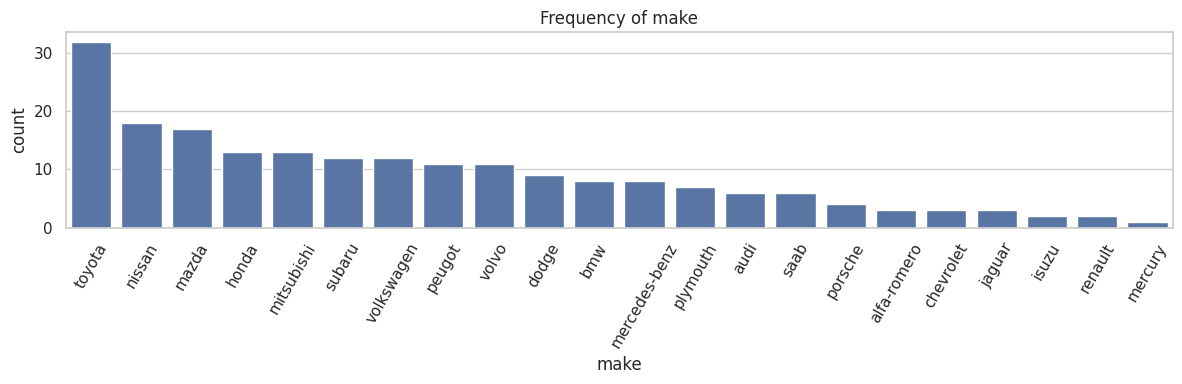

In [15]:
bar_cols = ["body-style", "drive-wheels", "engine-location", "num-of-cylinders", "aspiration", "fuel-system"]
fig, axes = plt.subplots(2, 3, figsize=(18, 9))
for ax, col in zip(axes.ravel(), bar_cols):
    sns.countplot(data=df, x=col, order=df[col].value_counts().index, ax=ax)
    ax.set_title(f"Frequency of {col}")
    ax.tick_params(axis="x", rotation=30)
plt.tight_layout()
plt.show()

plt.figure(figsize=(12, 4))
sns.countplot(data=df, x="make", order=df["make"].value_counts().index)
plt.xticks(rotation=60)
plt.title("Frequency of make")
plt.tight_layout()
plt.show()

The bar charts show the same imbalances as the frequency tables: a few categories (sedan, hatchback, fwd, front engine, four cylinders, mpfi and 2bbl fuel systems) hold most cars, and many categories contain only a handful of cars.

---
## Question 3: Average price by group
### 3.1 Drive-wheels and body-style

In [16]:
drive_price = df.groupby("drive-wheels")["price"].agg(["mean", "median", "std", "count"]).round(0).sort_values("mean", ascending=False)
body_price = df.groupby("body-style")["price"].agg(["mean", "median", "std", "count"]).round(0).sort_values("mean", ascending=False)
print("Average price by drive-wheels"); display(drive_price)
print("Average price by body-style"); display(body_price)

Average price by drive-wheels


,mean,median,std,count
drive-wheels,,,,
rwd,19758.0,16900.0,9083.0,75
4wd,10241.0,9006.0,3288.0,8
fwd,9245.0,8192.0,3346.0,118


Average price by body-style


,mean,median,std,count
body-style,,,,
hardtop,22208.0,19688.0,14556.0,8
convertible,21890.0,17084.0,11188.0,6
sedan,14460.0,11078.0,8523.0,94
wagon,12372.0,11694.0,5121.0,25
hatchback,9957.0,8672.0,4149.0,68


**Output:**
- **Drive-wheels:** rear-wheel drive has by far the highest average price (19,758), while front-wheel drive is the lowest (9,245). 4wd averages 10,241, close to fwd, but it has only 8 cars.
- **Body-style:** hardtop is highest (22,208) followed closely by convertible (21,890), and hatchback is lowest (9,957). Sedan (14,460) and wagon (12,372) sit in between.
- Standard deviations are large for hardtop (14,556) and convertible (11,188), and each has few cars (8 and 6), so those averages are less certain.

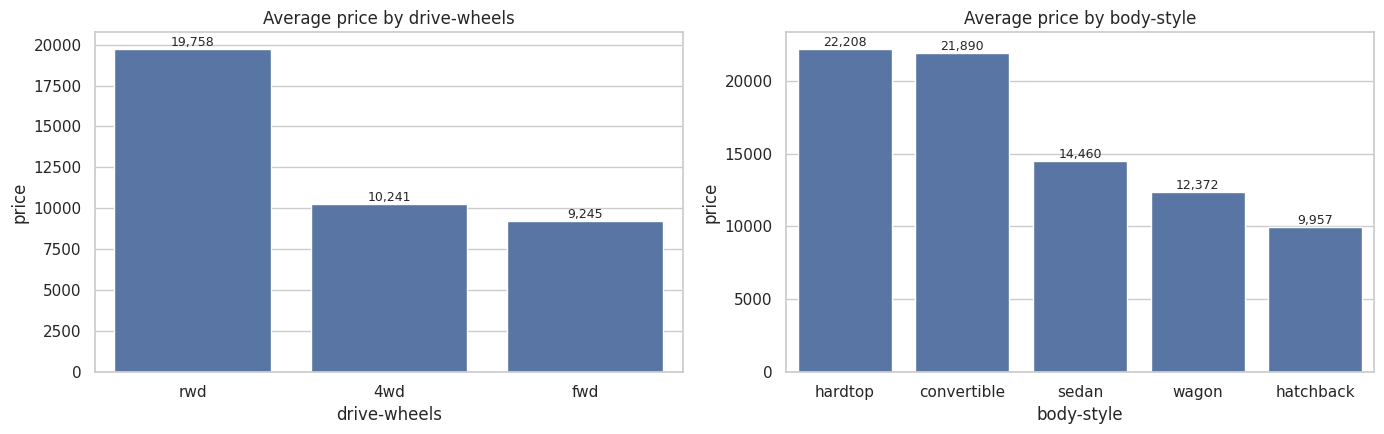

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
order_d = drive_price.index
sns.barplot(data=df, x="drive-wheels", y="price", order=order_d, estimator=np.mean, errorbar=None, ax=axes[0])
axes[0].set_title("Average price by drive-wheels")
order_b = body_price.index
sns.barplot(data=df, x="body-style", y="price", order=order_b, estimator=np.mean, errorbar=None, ax=axes[1])
axes[1].set_title("Average price by body-style")
for ax in axes:
    for p in ax.patches:
        ax.annotate(f"{p.get_height():,.0f}", (p.get_x() + p.get_width()/2, p.get_height()), ha="center", va="bottom", fontsize=9)
plt.tight_layout()
plt.show()

The bar charts confirm the ranking: rwd stands far above fwd and 4wd, and the sports-oriented body styles (hardtop, convertible) cost more than the everyday ones (sedan, wagon, hatchback).

### 3.2 Drive-wheels and body-style together

,drive-wheels,body-style,mean,count
9,rwd,hardtop,24203.0,7
8,rwd,convertible,23950.0,5
11,rwd,sedan,21712.0,36
12,rwd,wagon,16994.0,9
10,rwd,hatchback,14338.0,18
1,4wd,sedan,12647.0,3
3,fwd,convertible,11595.0,1
7,fwd,wagon,9997.0,12
6,fwd,sedan,9812.0,55
2,4wd,wagon,9096.0,4


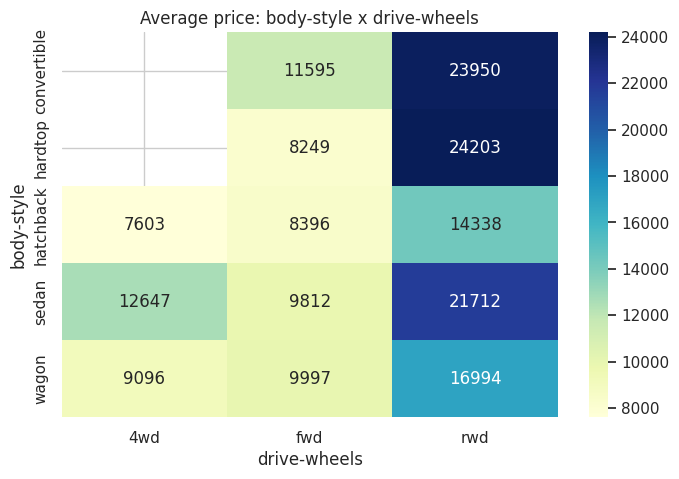

In [18]:
group_price = df.groupby(["drive-wheels", "body-style"])["price"].agg(["mean", "count"]).round(0).reset_index()
group_price = group_price.sort_values("mean", ascending=False)
display(group_price)

pivot_price = df.pivot_table(values="price", index="body-style", columns="drive-wheels", aggfunc="mean")
plt.figure(figsize=(8, 5))
sns.heatmap(pivot_price, annot=True, fmt=".0f", cmap="YlGnBu")
plt.title("Average price: body-style x drive-wheels")
plt.show()

Combining the two variables, the most expensive group is **rwd hardtop (24,203, n=7)**, followed by rwd convertible (23,950, n=5) and rwd sedan (21,712, n=36). The cheapest groups are 4wd hatchback (7,603, n=1), fwd hardtop (8,249, n=1) and fwd hatchback (8,396, n=49).
Within the same body style, rwd cars cost more than fwd cars (sedan 21,712 vs 9,812; hatchback 14,338 vs 8,396; wagon 16,994 vs 9,997). Several groups have only one or a few cars, so only the large groups (rwd sedan, fwd sedan, fwd hatchback) are dependable. The heatmap shows this as a darker band across the rwd column.

In [19]:
print("Drive-wheels  highest:", drive_price["mean"].idxmax(), drive_price["mean"].max(), "| lowest:", drive_price["mean"].idxmin(), drive_price["mean"].min())
print("Body-style    highest:", body_price["mean"].idxmax(), body_price["mean"].max(), "| lowest:", body_price["mean"].idxmin(), body_price["mean"].min())
top = group_price.iloc[0]; bot = group_price.iloc[-1]
print(f"Combined      highest: {top['drive-wheels']} + {top['body-style']} ({top['mean']:.0f}, n={top['count']:.0f})")
print(f"Combined      lowest : {bot['drive-wheels']} + {bot['body-style']} ({bot['mean']:.0f}, n={bot['count']:.0f})")

Drive-wheels  highest: rwd 19758.0 | lowest: fwd 9245.0
Body-style    highest: hardtop 22208.0 | lowest: hatchback 9957.0
Combined      highest: rwd + hardtop (24203, n=7)
Combined      lowest : 4wd + hatchback (7603, n=1)


**Answer to Question 3:**
- Highest average price: **rwd** (drive-wheels), **hardtop** (body-style), and **rwd + hardtop** (24,203) as a combination.
- Lowest average price: **fwd** (drive-wheels, 9,245), **hatchback** (body-style, 9,957), and **4wd + hatchback** (7,603) as a combination, but that group has a single car. Among well-populated groups the lowest is fwd + hatchback (8,396, n=49).

---
## Question 4: Effect of the independent variables on price
### 4a. Continuous variables vs price

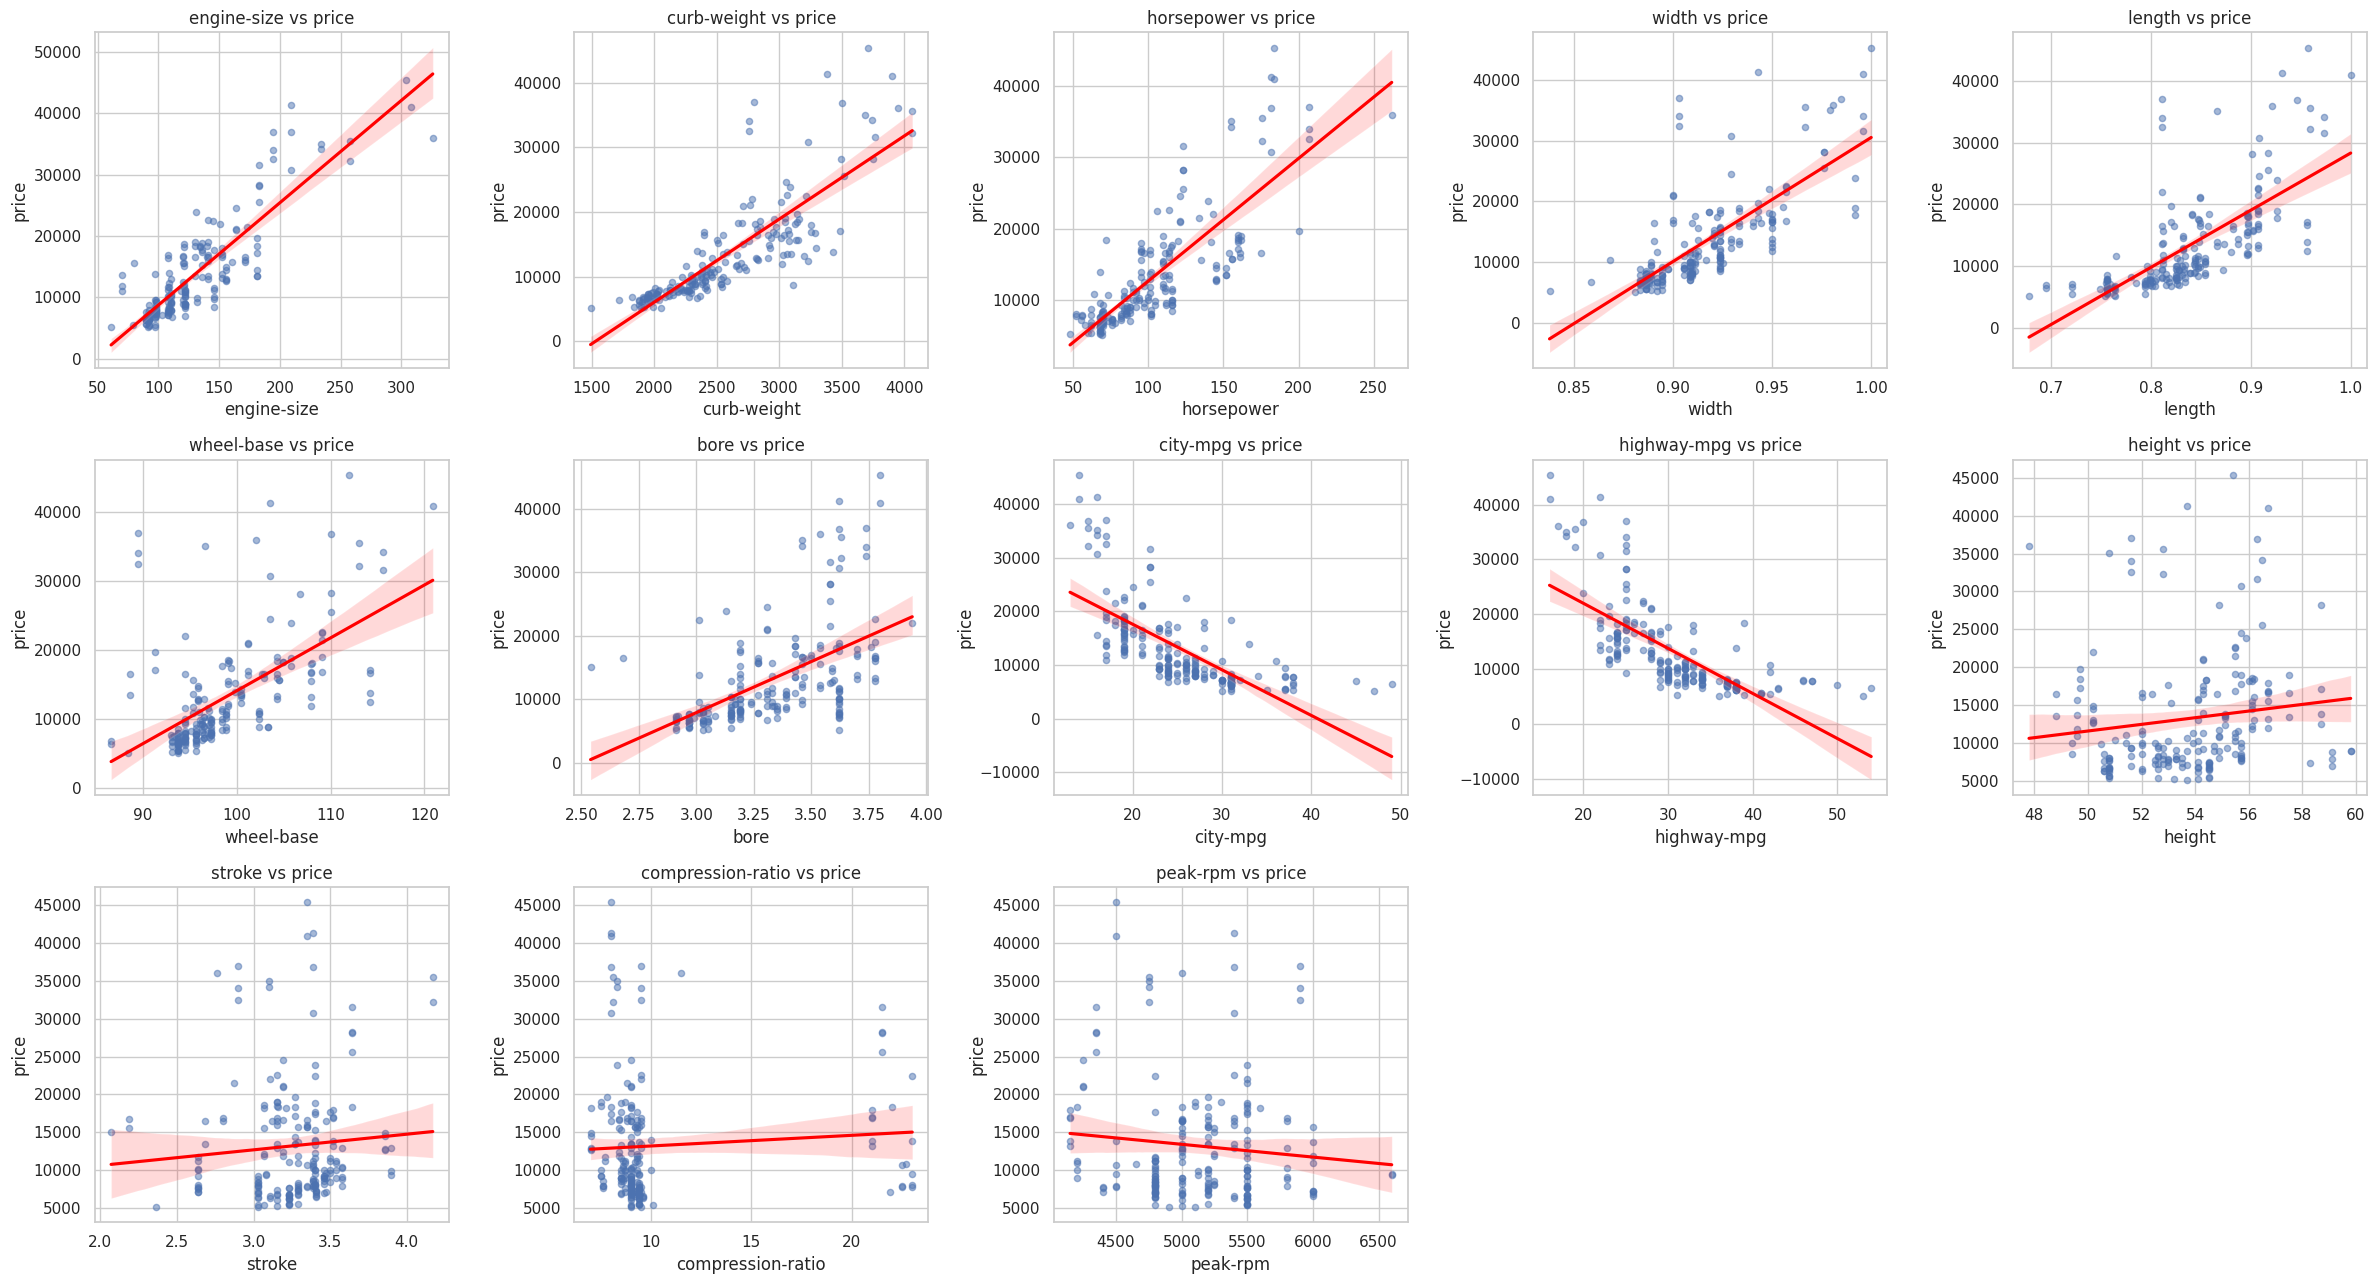

In [20]:
reg_cols = ["engine-size", "curb-weight", "horsepower", "width", "length", "wheel-base",
            "bore", "city-mpg", "highway-mpg", "height", "stroke", "compression-ratio", "peak-rpm"]
fig, axes = plt.subplots(3, 5, figsize=(24, 13))
for ax, col in zip(axes.ravel(), reg_cols):
    sns.regplot(data=df, x=col, y="price", scatter_kws={"alpha": 0.5, "s": 20}, line_kws={"color": "red"}, ax=ax)
    ax.set_title(f"{col} vs price")
for ax in axes.ravel()[len(reg_cols):]:
    ax.axis("off")
plt.tight_layout()
plt.show()

The scatter plots with fitted lines show clear, mostly linear relationships:
- Positive and strong: `engine-size`, `curb-weight`, `horsepower`, `width`, `length`. Larger, heavier, more powerful cars cost more.
- Negative: `city-mpg` and `highway-mpg`. Cars with better fuel economy are cheaper, because economy cars are small with small engines.
- Essentially flat: `height`, `stroke`, `compression-ratio`, `peak-rpm`.

In [21]:
rows = []
for col in cont_cols:
    if col == "price":
        continue
    r, p = stats.pearsonr(df[col], df["price"])
    rho, _ = stats.spearmanr(df[col], df["price"])
    rows.append([col, r, rho, p])
corr_table = pd.DataFrame(rows, columns=["variable", "pearson_r", "spearman_rho", "p_value"])
corr_table["abs_r"] = corr_table["pearson_r"].abs()
corr_table = corr_table.sort_values("abs_r", ascending=False).drop(columns="abs_r").reset_index(drop=True)
corr_table.round(4)

,variable,pearson_r,spearman_rho,p_value
0,engine-size,0.8723,0.8284,0.0000
1,curb-weight,0.8344,0.9138,0.0000
2,horsepower,0.8096,0.8491,0.0000
3,city-L/100km,0.7899,0.8313,0.0000
4,width,0.7513,0.8121,0.0000
5,highway-mpg,-0.7047,-0.8273,0.0000
6,length,0.6906,0.8103,0.0000
7,city-mpg,-0.6866,-0.8313,0.0000
8,wheel-base,0.5846,0.6818,0.0000
9,bore,0.5432,0.6459,0.0000


**Output (Pearson correlation with price, with p-values):**
- Strongest: `engine-size` (0.872), `curb-weight` (0.834), `horsepower` (0.810), `city-L/100km` (0.790), `width` (0.751). All have p < 0.001.
- Negative: `highway-mpg` (-0.705) and `city-mpg` (-0.687).
- Weak or not significant at the 5% level: `height` (p=0.055), `normalized-losses` (p=0.058), `peak-rpm` (p=0.15), `stroke` (p=0.25), `compression-ratio` (p=0.32).
Spearman rank correlations agree (for example `curb-weight` is 0.914), so the relationships are not driven only by outliers.
Note: `city-L/100km` is just a unit conversion of `city-mpg`, so it adds no new information. `normalized-losses` was already mean-filled in the source file (41 cars share the value 122), so its weak correlation is unreliable and it is not used as a predictor.

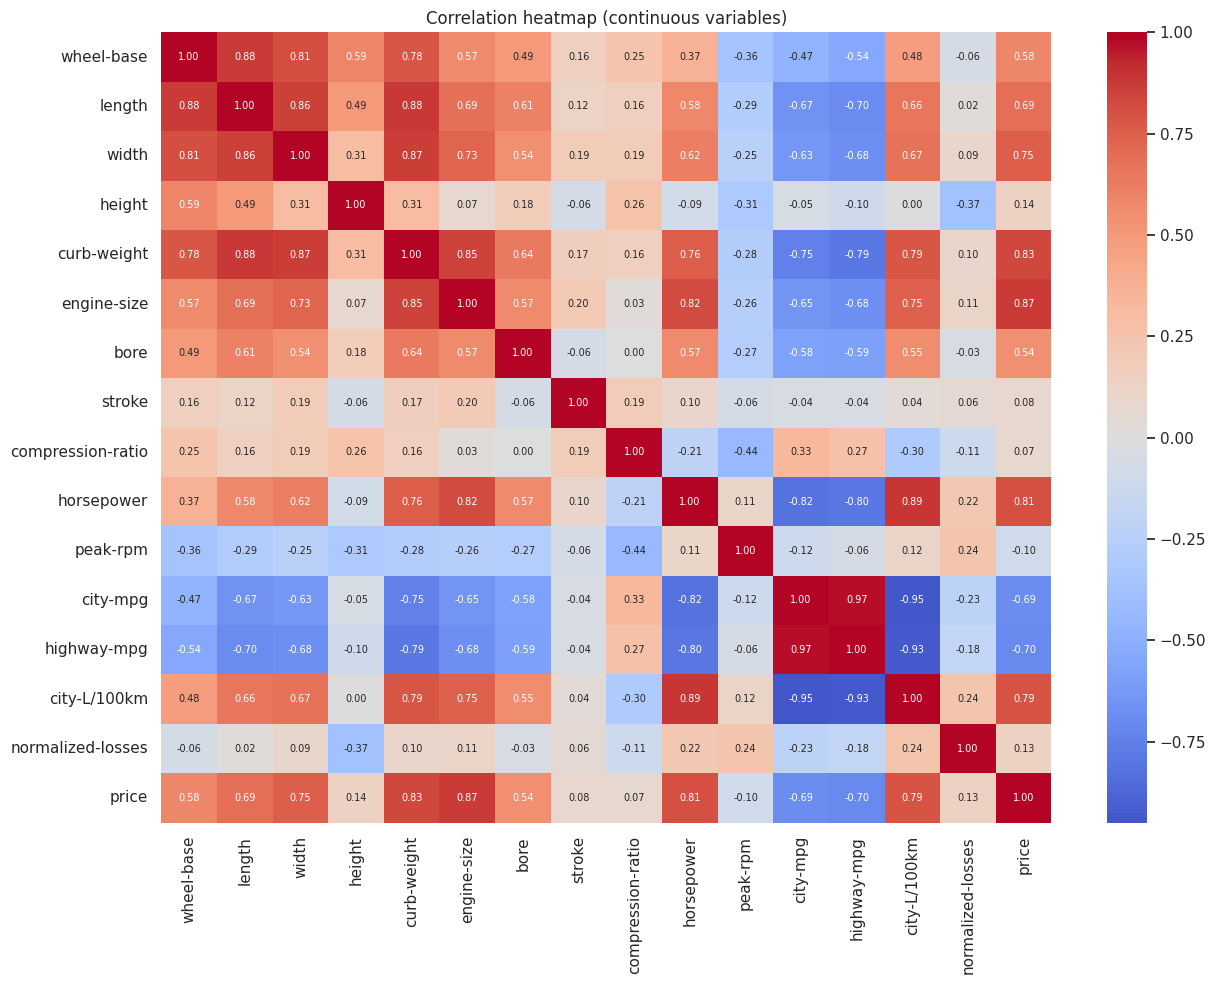

In [22]:
plt.figure(figsize=(13, 10))
sns.heatmap(df[cont_cols].corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0, annot_kws={"size": 7})
plt.title("Correlation heatmap (continuous variables)")
plt.tight_layout()
plt.show()

The heatmap shows the predictors are strongly correlated with each other (engine-size, curb-weight, horsepower, length and width all rise together, and mpg falls with them). This is multicollinearity: these variables carry overlapping information, so their separate effects cannot be fully distinguished, and their individual importance in a model gets shared between them.

### 4b. Categorical variables vs price

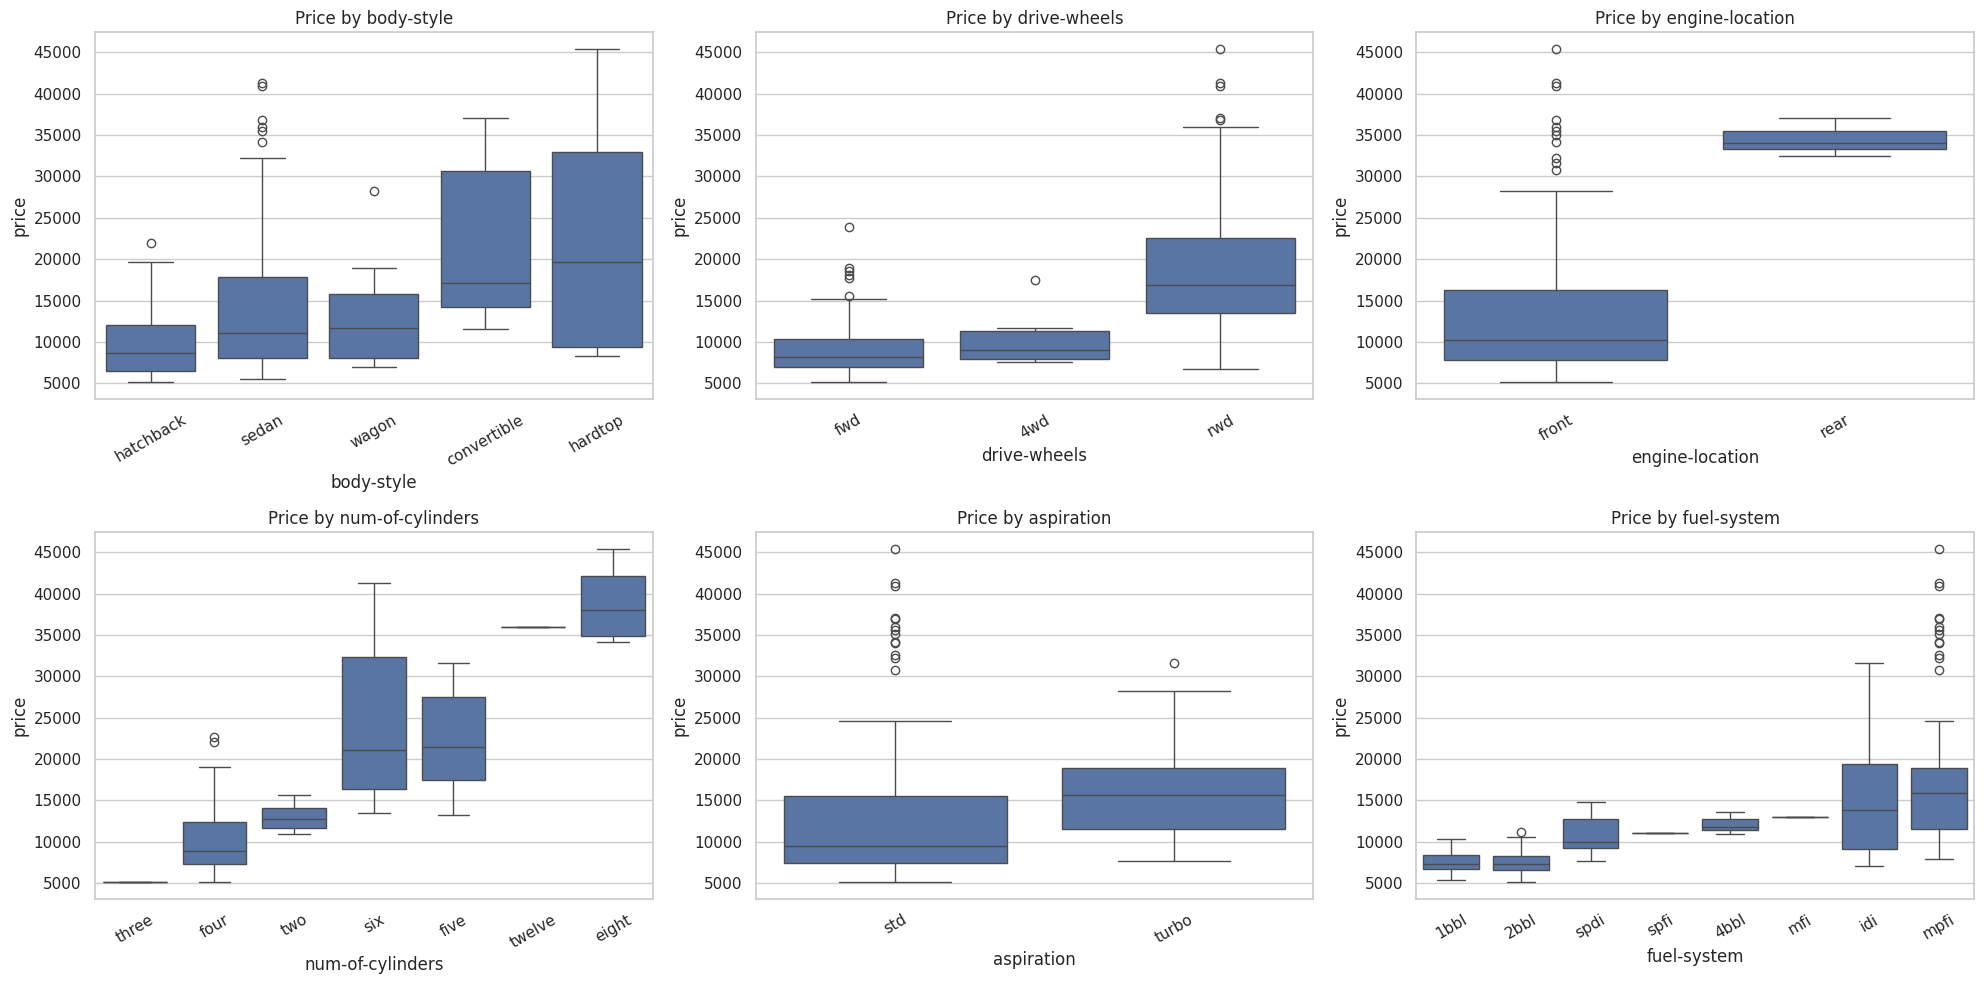

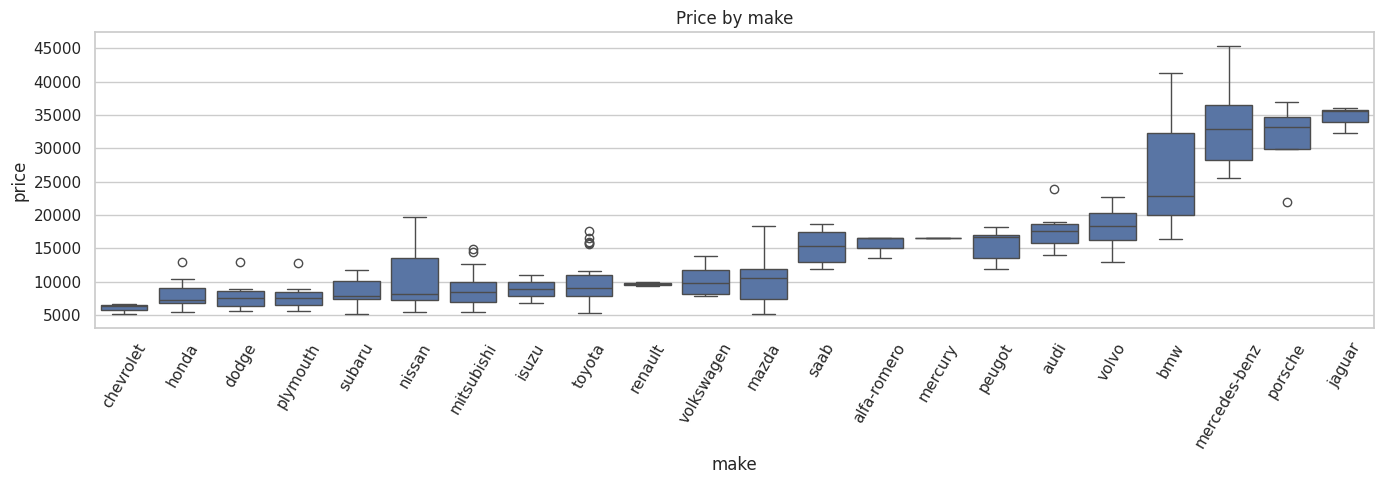

In [23]:
fig, axes = plt.subplots(2, 3, figsize=(20, 10))
for ax, col in zip(axes.ravel(), bar_cols):
    sns.boxplot(data=df, x=col, y="price", order=df.groupby(col)["price"].median().sort_values().index, ax=ax)
    ax.set_title(f"Price by {col}")
    ax.tick_params(axis="x", rotation=30)
plt.tight_layout()
plt.show()

plt.figure(figsize=(14, 5))
sns.boxplot(data=df, x="make", y="price", order=df.groupby("make")["price"].median().sort_values().index)
plt.xticks(rotation=60)
plt.title("Price by make")
plt.tight_layout()
plt.show()

The boxplots show clear differences in price between groups for `drive-wheels`, `num-of-cylinders`, `engine-location`, `fuel-system` and `make`. Cars with 8, 12, 5 and 6 cylinders sit well above four-cylinder cars, rear-engine cars are far above front-engine cars, and the luxury makes (jaguar, mercedes-benz, porsche, bmw) sit far above the rest. `aspiration` shows only a modest gap (turbo 16,255 vs standard 12,542).

In [24]:
test_cols = ["make", "body-style", "drive-wheels", "engine-location", "engine-type",
             "num-of-cylinders", "fuel-system", "aspiration", "num-of-doors"]
rows = []
for col in test_cols:
    groups = [g["price"].values for _, g in df.groupby(col)]
    F, p_anova = stats.f_oneway(*groups)
    H, p_kw = stats.kruskal(*groups)
    # eta-squared: share of price variance explained by the category
    grand = df["price"].mean()
    ss_between = sum(len(g) * (g.mean() - grand) ** 2 for g in groups)
    eta2 = ss_between / ((df["price"] - grand) ** 2).sum()
    rows.append([col, df[col].nunique(), F, p_anova, p_kw, eta2])
cat_tests = pd.DataFrame(rows, columns=["variable", "n_levels", "F", "anova_p", "kruskal_p", "eta_squared"])
cat_tests.sort_values("eta_squared", ascending=False).reset_index(drop=True).round(4)

,variable,n_levels,F,anova_p,kruskal_p,eta_squared
0,make,22,33.2321,0.0000,0.0000,0.7959
1,num-of-cylinders,7,54.9437,0.0000,0.0000,0.6295
2,drive-wheels,3,67.9541,0.0000,0.0000,0.4070
3,fuel-system,8,15.0244,0.0000,0.0000,0.3527
4,engine-type,6,9.8451,0.0000,0.0000,0.2016
5,body-style,5,9.1288,0.0000,0.0000,0.1570
6,engine-location,2,24.4956,0.0000,0.0054,0.1096
7,aspiration,2,6.6313,0.0107,0.0000,0.0322
8,num-of-doors,2,0.3590,0.5497,0.0644,0.0018


**Output (ANOVA and Kruskal-Wallis tests of price across categories, with eta-squared as the share of price variance explained):**
- `make` explains the most variance (eta-squared 0.80), then `num-of-cylinders` (0.63), `drive-wheels` (0.41), `fuel-system` (0.35), `engine-type` (0.20), `body-style` (0.16) and `engine-location` (0.11).
- `aspiration` is significant but weak (0.03).
- `num-of-doors` is **not** significant (ANOVA p=0.55, eta-squared 0.002), so the number of doors does not meaningfully change price.
Caution: `make` has 22 levels, many with only 1-4 cars, which inflates its eta-squared a little.

### 4c. Two categorical variables (drive-wheels and body-style)

In [25]:
ct = pd.crosstab(df["drive-wheels"], df["body-style"])
print("Counts: drive-wheels x body-style")
display(ct)

chi2, p, dof, expected = stats.chi2_contingency(ct)
n = ct.values.sum()
cramers_v = np.sqrt(chi2 / (n * (min(ct.shape) - 1)))
print(f"Chi-square = {chi2:.2f}, dof = {dof}, p = {p:.4f}, Cramer's V = {cramers_v:.3f}")
print(f"Cells with expected count < 5: {(expected < 5).sum()} of {expected.size}")

Counts: drive-wheels x body-style


body-style,convertible,hardtop,hatchback,sedan,wagon
drive-wheels,,,,,
4wd,0,0,1,3,4
fwd,1,1,49,55,12
rwd,5,7,18,36,9


Chi-square = 29.11, dof = 8, p = 0.0003, Cramer's V = 0.269
Cells with expected count < 5: 9 of 15


The cross-tabulation shows that drive-wheels and body-style are not independent (chi-square = 29.11, df = 8, p = 0.0003). Cramer's V is 0.27, a moderate association. For example, convertibles and hardtops are mostly rwd (12 of 14), while hatchbacks are mostly fwd (49 of 68).
Caution: 9 of the 15 cells have an expected count below 5, so the chi-square p-value should be read as indicative rather than exact.

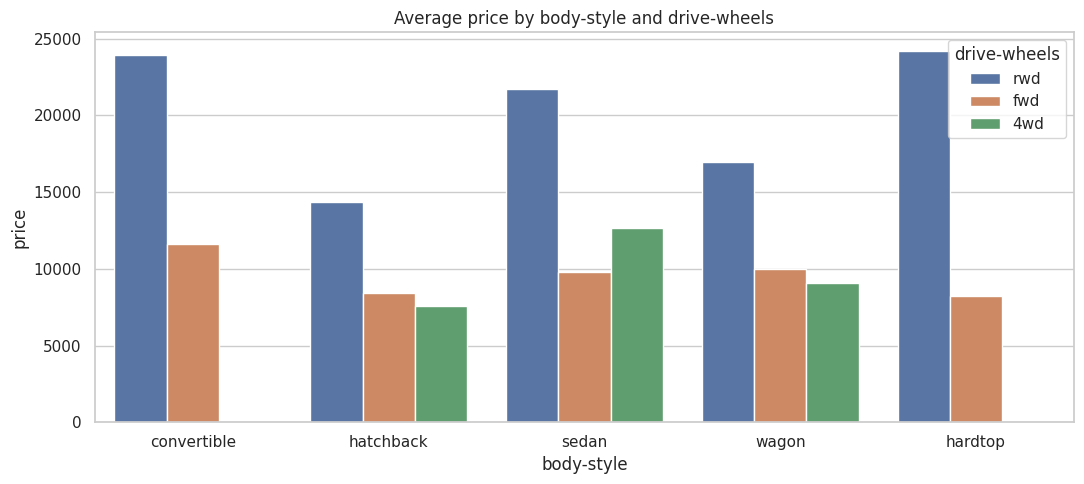

In [26]:
plt.figure(figsize=(11, 5))
sns.barplot(data=df, x="body-style", y="price", hue="drive-wheels", errorbar=None)
plt.title("Average price by body-style and drive-wheels")
plt.tight_layout()
plt.show()

Within every body style that has both, rwd cars are more expensive than fwd cars. Part of this gap reflects that rwd cars are typically larger and more powerful, and more often luxury makes, so drive type is partly standing in for those other factors rather than acting alone.

---
## Question 5: Main price drivers, feature selection and recommendation
Three feature-selection methods are used so the conclusion does not depend on one technique:
1. Correlation and mutual information (numeric variables)
2. Permutation importance from a Random Forest (all variables, tested on unseen data)
3. Impurity-based Random Forest importance, with the one-hot columns summed back to the original variable

In [27]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.inspection import permutation_importance
from sklearn.feature_selection import mutual_info_regression

# diesel/gas duplicate fuel information and city-L/100km is a transformation of city-mpg, so they are left out
num_features = ["wheel-base", "length", "width", "height", "curb-weight", "engine-size", "bore", "stroke",
                "compression-ratio", "horsepower", "peak-rpm", "city-mpg", "highway-mpg"]
cat_features = ["make", "body-style", "drive-wheels", "engine-location", "engine-type",
                "num-of-cylinders", "fuel-system", "aspiration"]

# Method 1: correlation / mutual information for numeric features
mi = pd.Series(mutual_info_regression(df[num_features], df["price"], random_state=42), index=num_features)
corr_abs = df[num_features].corrwith(df["price"]).abs()
rank_tbl = pd.DataFrame({"abs_pearson": corr_abs, "mutual_info": mi}).sort_values("mutual_info", ascending=False)
rank_tbl.round(3)

,abs_pearson,mutual_info
curb-weight,0.834,0.896
horsepower,0.810,0.861
highway-mpg,0.705,0.856
engine-size,0.872,0.826
city-mpg,0.687,0.737
width,0.751,0.686
wheel-base,0.585,0.598
length,0.691,0.573
bore,0.543,0.461
stroke,0.082,0.363


Both methods rank `curb-weight`, `horsepower`, `engine-size` and the mpg variables near the top. Mutual information (which also detects non-linear relationships) puts `curb-weight` first (0.896), then `horsepower` (0.861), `highway-mpg` (0.856) and `engine-size` (0.826). By Pearson correlation `engine-size` is first (0.872). `stroke`, `height`, `peak-rpm` and `compression-ratio` rank at the bottom in both.

Random Forest R2 on test data: 0.929


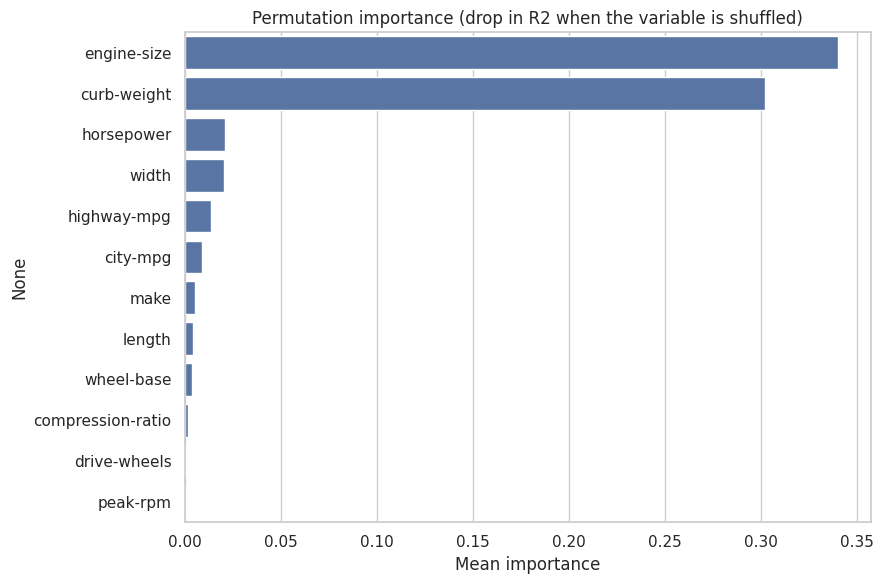

engine-size          0.3401
curb-weight          0.3019
horsepower           0.0208
width                0.0204
highway-mpg          0.0137
city-mpg             0.0088
make                 0.0055
length               0.0040
wheel-base           0.0039
compression-ratio    0.0014
drive-wheels         0.0008
peak-rpm             0.0007
dtype: float64

In [28]:
X = df[num_features + cat_features]
y = df["price"]
pre = ColumnTransformer([("num", "passthrough", num_features),
                         ("cat", OneHotEncoder(handle_unknown="ignore"), cat_features)])
model = Pipeline([("pre", pre), ("rf", RandomForestRegressor(n_estimators=300, random_state=42))])

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
model.fit(X_train, y_train)
print("Random Forest R2 on test data:", round(model.score(X_test, y_test), 3))

# Method 2: permutation importance on original (un-encoded) columns, so each variable gets one score
perm = permutation_importance(model, X_test, y_test, n_repeats=30, random_state=42)
perm_imp = pd.Series(perm.importances_mean, index=X.columns).sort_values(ascending=False)

plt.figure(figsize=(9, 6))
sns.barplot(x=perm_imp.head(12).values, y=perm_imp.head(12).index)
plt.title("Permutation importance (drop in R2 when the variable is shuffled)")
plt.xlabel("Mean importance")
plt.tight_layout()
plt.show()
perm_imp.head(12).round(4)

A Random Forest using all variables predicts price well on unseen cars (R-squared = 0.929). Permutation importance, which measures how much accuracy drops when a variable is shuffled, shows that **`engine-size` (0.340) and `curb-weight` (0.302)** matter far more than anything else. The next group (`horsepower`, `width`, `highway-mpg`, `city-mpg`, `make`) is much smaller. Because correlated variables share credit, small values do not mean the others are irrelevant.

In [29]:
# Method 3: impurity-based importance, one-hot columns summed back to the original variable
ohe = model.named_steps["pre"].named_transformers_["cat"]
names = num_features + list(ohe.get_feature_names_out(cat_features))
imp = pd.Series(model.named_steps["rf"].feature_importances_, index=names)
grouped = {}
for n, v in imp.items():
    base = next((c for c in cat_features if n.startswith(c + "_")), n)
    grouped[base] = grouped.get(base, 0) + v
grouped = pd.Series(grouped).sort_values(ascending=False)
grouped.head(10).round(3)

curb-weight    0.428
engine-size    0.326
highway-mpg    0.050
horsepower     0.047
city-mpg       0.035
width          0.027
make           0.018
wheel-base     0.016
length         0.008
peak-rpm       0.008
dtype: float64

The impurity-based importance, with categories added back together, agrees: `curb-weight` (0.428) and `engine-size` (0.326) together account for about 75% of the model's importance, followed by `highway-mpg`, `horsepower`, `city-mpg`, `width` and `make`.

In [30]:
# Does a simple model on just the top predictors do almost as well?
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import cross_val_score, KFold
kf = KFold(n_splits=5, shuffle=True, random_state=42)
for feats in [["engine-size"], ["engine-size", "curb-weight"], ["engine-size", "curb-weight", "horsepower"],
              ["engine-size", "curb-weight", "horsepower", "highway-mpg", "width"]]:
    r2 = cross_val_score(LinearRegression(), df[feats], df["price"], cv=kf, scoring="r2").mean()
    print(f"{', '.join(feats):60s} CV R2 = {r2:.3f}")

engine-size                                                  CV R2 = 0.683
engine-size, curb-weight                                     CV R2 = 0.732
engine-size, curb-weight, horsepower                         CV R2 = 0.741
engine-size, curb-weight, horsepower, highway-mpg, width     CV R2 = 0.753


A plain linear regression with cross-validation (shuffled folds) shows how few variables are needed. `engine-size` alone explains about 68% of price variation (cross-validated R-squared 0.683); adding `curb-weight` raises it to 0.732, adding `horsepower` to 0.741, and five variables give 0.753. The gain beyond the first two or three variables is small, which supports a short list of main drivers.
(The linear model scores below the Random Forest because brand and non-linear effects are not captured.)

---
## Summary of findings and recommendation for a car dealer

### Main variables that drive price
All three feature-selection methods agree on the ranking:

| Rank | Variable | Evidence |
|---|---|---|
| 1 | **engine-size** | r = 0.87; highest permutation importance (0.340); alone explains about 68% of price variation |
| 2 | **curb-weight** | r = 0.83; top mutual information (0.896); top impurity importance (0.428) |
| 3 | **horsepower** | r = 0.81; high mutual information (0.861) |
| 4 | **width / fuel economy** (`highway-mpg`, `city-mpg`) | r = 0.75 / -0.70 / -0.69; moderate importance, but strongly overlapping with size and power |
| Categorical | **make**, **num-of-cylinders**, **drive-wheels** | eta-squared 0.80, 0.63, 0.41 |

Variables with little or no effect: `num-of-doors`, `compression-ratio`, `peak-rpm`, `stroke`, `height`, `normalized-losses`. `aspiration` and `body-style` have only a small effect.

### Recommendation for the dealer
1. **Price mainly by engine size and weight.** Larger-engine, heavier cars command higher prices, and these two variables alone explain most of the variation in price. Use them as the starting point for a price.
2. **Add a premium for horsepower and for rear-wheel drive.** Rear-wheel-drive cars average about 19,758 against 9,245 for front-wheel drive, and in each body style they cost more. Treat this as a marker of performance and size rather than a reason to add the same amount to every rwd car.
3. **Apply a brand premium.** Jaguar, Mercedes-Benz, Porsche and BMW sit well above the rest of the market, and `make` explains about 80% of price differences between groups. The same specification will sell for more under a premium badge.
4. **Price economy cars at the low end.** Fuel-efficient, small-engine fwd hatchbacks are the cheapest segment (average about 8,400-10,000) and they are the most numerous, so competition is high and margins should be set carefully.
5. **Do not pay for number of doors, compression ratio, peak rpm, stroke or height.** They show no meaningful relationship with price.
6. **Treat the convertible, hardtop, 4wd and rear-engine averages with care.** These groups have very few cars (1-8), so their averages are unstable.

### Limitations
This is a sample of 201 cars, and the results show association, not causation. Predictors such as engine size, weight and horsepower are strongly correlated with each other, so their separate effects cannot be fully separated. Prices are as recorded in the dataset and may not match the current market.